# Rossmann Store Sales. Разбор результатов

Проверяем, помогает ли история продаж точнее прогнозировать дневную выручку.
Результаты для ноутбука готовит команда `python -m src.run_baseline` из корня проекта.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
config = json.loads((root / "configs/baseline.json").read_text(encoding="utf-8"))
output = root / config["output_dir"]
report = json.loads((output / "metrics.json").read_text(encoding="utf-8"))
predictions = pd.read_csv(output / "predictions.csv", parse_dates=["Date"])
scored = predictions.loc[predictions["Sales"] > 0].copy()

plt.style.use("seaborn-v0_8-whitegrid")

## Что есть в данных

Одна строка в таблице описывает один день одного магазина. Если `Open = 0`, магазин в этот день не работал, поэтому его выручка равна нулю. В данных есть и 54 случая, когда магазин был открыт, а выручка записана как нулевая.

По правилам контеста RMSPE считаем только для дней с положительной выручкой. На графиках ниже тоже берем только такие дни.

У 180 магазинов с июля по декабрь 2014 года вообще нет записей. Из-за этого для некоторых дат нельзя взять выручку за тот же день недели год назад.

,Значение
Дни всех магазинов,1017209
Магазины,1115
Начало,2013-01-01
Конец,2015-07-31
Пустые ячейки в имеющихся строках,0
Строки с нулевой выручкой,172871
"Дни, когда магазин не работал",172817
Дни работы с нулевой выручкой,54


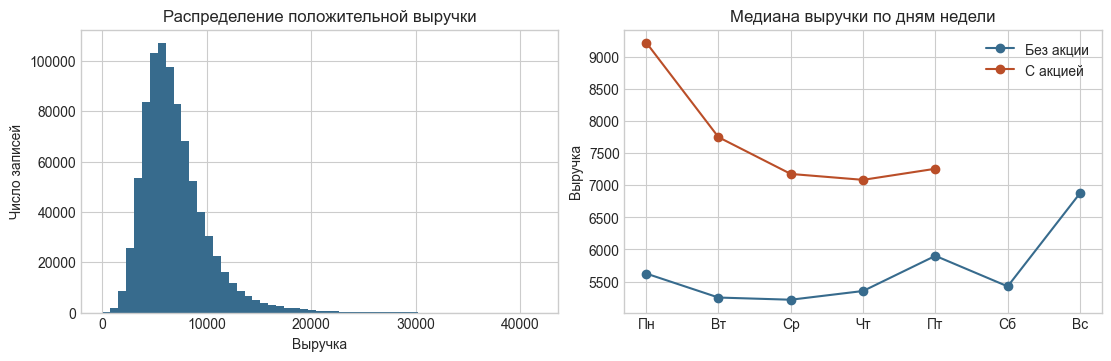

In [2]:
data = report["data"]
display(pd.Series({
    "Дни всех магазинов": data["rows"],
    "Магазины": data["stores"],
    "Начало": data["first_date"],
    "Конец": data["last_date"],
    "Пустые ячейки в имеющихся строках": sum(data["missing"].values()),
    "Строки с нулевой выручкой": data["zero_sales"],
    "Дни, когда магазин не работал": data["closed_days"],
    "Дни работы с нулевой выручкой": data["open_zero_sales"],
}, name="Значение").to_frame())

sales = pd.read_csv(
    root / config["data_path"],
    usecols=["Sales", "DayOfWeek", "Promo"],
)
positive = sales.loc[sales["Sales"] > 0]
by_day = positive.groupby(["DayOfWeek", "Promo"])["Sales"].median().unstack()
by_day.index = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
by_day.columns = ["Без акции", "С акцией"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
axes[0].hist(positive["Sales"], bins=55, color="#376b8d")
axes[0].set(title="Распределение положительной выручки", xlabel="Выручка", ylabel="Число записей")
by_day.plot(ax=axes[1], marker="o", color=["#376b8d", "#ba4e28"])
axes[1].set(title="Медиана выручки по дням недели", xlabel="", ylabel="Выручка")
plt.show()

На графике слева около 93% положительных значений дневной выручки лежат между 2000 и 12 000. Половина значений ниже 6369.

Справа сравниваем дни с акциями и без них. Например, по понедельникам медиана выручки составляет 5625 без акции и 9225 с акцией. В выходные в данных с положительной выручкой нет записей об акциях, поэтому оранжевая линия заканчивается на пятнице.

## Помогает ли история продаж

Обе версии линейной регрессии используют номер магазина, день недели, месяц и запланированную акцию. Второй версии дополнительно даем шесть признаков из прошлых продаж.

Сравниваем прогнозы на одних и тех же днях с положительной выручкой. Основная проверка проходит на последних 42 днях в `train.csv`. Берем еще два более ранних периода, чтобы проверить, повторяется ли результат. Считаем, что в момент прогноза нам известны акции и дни работы каждого магазина на все шесть недель.

,Дни с выручкой,"RMSPE, %",MAE
Без истории,40282.0,20.33,931.78
С историей,40282.0,15.61,754.71


На сколько снизился RMSPE: 23.20%
95%-й бутстрап-интервал для снижения: от 21.39% до 25.01%


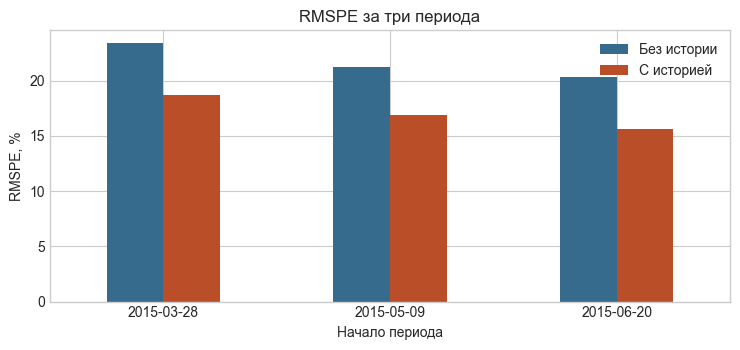

In [3]:
names = {"no_history": "Без истории", "with_history": "С историей"}
main = pd.DataFrame({names[key]: report["experiments"][key] for key in names}).T
main["rmspe"] *= 100
display(main.rename(columns={"rows": "Дни с выручкой", "rmspe": "RMSPE, %", "mae": "MAE"}).round(2))

improvement = report["relative_improvement"] * 100
lower, upper = [bound * 100 for bound in report["bootstrap_95_ci"]]
print(f"На сколько снизился RMSPE: {improvement:.2f}%")
print(f"95%-й бутстрап-интервал для снижения: от {lower:.2f}% до {upper:.2f}%")

windows = pd.DataFrame(report["backtest"])
scores = windows.set_index("start")[list(names)].rename(columns=names) * 100
ax = scores.plot(kind="bar", figsize=(7.5, 3.6), color=["#376b8d", "#ba4e28"], rot=0)
ax.set(title="RMSPE за три периода", xlabel="Начало периода", ylabel="RMSPE, %")
plt.tight_layout()
plt.show()

С историей продаж RMSPE ниже на всех трех периодах. На последнем он снизился на 23,2% при согласованном пороге 5%.

Бутстрап показывает, насколько результат на последних 42 днях зависит от того, какие магазины попали в выборку. Два более ранних периода помогают проверить результат на других датах.

## Магазины из официального теста

Для основной проверки мы отложили 42 дня из `train.csv`. В официальном `test.csv` даты идут позже, их 48, а магазинов меньше.

Для дополнительной проверки оставляем те же 42 дня, но считаем ошибку только по 856 магазинам из официального теста. У них добавление истории снизило RMSPE с 18,36% до 14,96%.

In [4]:
official = report["official_test"]
print(f'Официальный тест: {official["first_date"]} по {official["last_date"]}')
print(f'Дней: {official["days"]}, магазинов: {official["stores"]}')
subset = pd.DataFrame(official["local_subset"]).T.rename(index=names)
subset["rmspe"] *= 100
display(subset.rename(columns={"rows": "Дни с выручкой", "rmspe": "RMSPE, %", "mae": "MAE"}).round(2))

Официальный тест: 2015-08-01 по 2015-09-17
Дней: 48, магазинов: 856


,Дни с выручкой,"RMSPE, %",MAE
Без истории,30960.0,18.36,911.63
С историей,30960.0,14.96,752.16


## Линейная регрессия с L2-регуляризацией

L2 добавляет штраф за большие коэффициенты модели. Взяли `alpha=100` до прогона и сравнили версии на тех же магазинах и датах.

In [5]:
l2 = report["regularization"]
comparison = pd.DataFrame({
    "Без регуляризации": {names[key]: 100 * report["experiments"][key]["rmspe"] for key in names},
    "С регуляризацией": {names[key]: 100 * l2[key]["rmspe"] for key in names},
})
print(f'Параметр L2: {l2["alpha"]:g}. Все значения в таблице в процентах RMSPE.')
display(comparison.round(3))

Параметр L2: 100. Все значения в таблице в процентах RMSPE.


,Без регуляризации,С регуляризацией
Без истории,20.328,21.018
С историей,15.613,15.733


При `alpha=100` RMSPE вырос у обеих моделей. Средняя абсолютная ошибка модели с историей немного снизилась. Мы сравниваем модели по RMSPE, поэтому для основного эксперимента оставляем модель без регуляризации.

## Три исследовательских вопроса

1. Помогает ли информация о тренде?
2. Добавляют ли прошлогодние продажи полезную информацию?
3. Насколько прогноз чувствителен к разовым всплескам в истории?

Для первого вопроса сравниваем прогнозы с трендом и без него. Для второго сравниваем прогнозы с выручкой за дату 364 дня назад и без нее. Ошибку считаем на днях, для которых такая запись есть.

Всплеском считаем день, когда выручка была хотя бы втрое выше обычной для этого магазина и дня недели. За обычную выручку берем медиану. Выбрали магазины, где всплески были, но занимали не больше 1% дней с положительной выручкой. Для них сравниваем среднее с медианой и отдельно смотрим, насколько меняются прогнозы после удаления всплесков из истории.

In [6]:
labels = {
    "trend": "Без тренда / с трендом",
    "last_year": "Без прошлого года / с прошлым годом",
    "spikes": "Среднее / медиана для магазинов со всплесками",
}
checks = []
for key, label in labels.items():
    first, second = report["research_checks"][key].values()
    checks.append({
        "Сравнение": label,
        "Дни с выручкой": first["rows"],
        "RMSPE варианта 1, %": first["rmspe"] * 100,
        "RMSPE варианта 2, %": second["rmspe"] * 100,
    })
display(pd.DataFrame(checks).round(3))

,Сравнение,Дни с выручкой,"RMSPE варианта 1, %","RMSPE варианта 2, %"
0,Без тренда / с трендом,40282,15.607,15.613
1,Без прошлого года / с прошлым годом,35252,16.229,15.588
2,Среднее / медиана для магазинов со всплесками,1363,20.078,20.344


Тренд почти не изменил RMSPE. Прошлогодняя выручка снизила ошибку на днях, для которых она была известна.

У 38 магазинов со всплесками среднее дало чуть меньшую ошибку, чем медиана. Дальше проверяем, насколько меняется прогноз одной и той же модели, если убрать всплески из истории перед расчетом признаков.

,Дни с выручкой,"RMSPE, %",MAE
История со всплесками,1363.0,20.344,720.874
Без всплесков,1363.0,20.297,720.063


Убрали всплесков из истории: 55
Половина прогнозов изменилась не более чем на 1.7
90% прогнозов изменились не более чем на 10.6


,Store,Date,Sales,with_history,history_without_spikes
26836,303,2015-07-14,7797,9333.7,7006.5


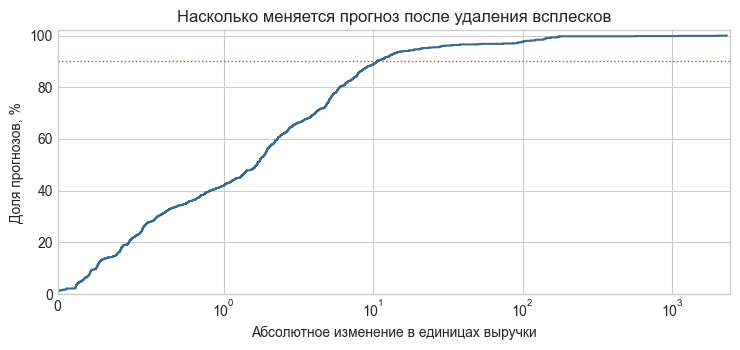

In [7]:
stress = report["spike_sensitivity"]
comparison = pd.DataFrame({
    "История со всплесками": stress["original"],
    "Без всплесков": stress["without_spikes"],
}).T
comparison["rmspe"] *= 100
display(comparison.rename(columns={"rows": "Дни с выручкой", "rmspe": "RMSPE, %", "mae": "MAE"}).round(3))

print(f'Убрали всплесков из истории: {stress["removed_rows"]}')
print(f'Половина прогнозов изменилась не более чем на {stress["median_absolute_change"]:.1f}')
print(f'90% прогнозов изменились не более чем на {stress["p90_absolute_change"]:.1f}')

changed = scored.dropna(subset=["history_without_spikes"])
change = (changed["history_without_spikes"] - changed["with_history"]).abs().sort_values()
largest = changed.loc[[change.idxmax()], ["Store", "Date", "Sales", "with_history", "history_without_spikes"]]
display(largest.round(1))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
share = 100 * change.rank(method="max", pct=True)
ax.step(change, share, where="post", color="#376b8d")
ax.axhline(90, color="#ba4e28", linestyle=":", linewidth=1)
ax.set_xscale("symlog", linthresh=1)
ax.set(
    xlim=(0, None),
    ylim=(0, 102),
    title="Насколько меняется прогноз после удаления всплесков",
    xlabel="Абсолютное изменение в единицах выручки",
    ylabel="Доля прогнозов, %",
)
plt.tight_layout()
plt.show()

После удаления 55 всплесков половина прогнозов изменилась максимум на 1,7 единицы выручки, а 90% прогнозов изменились максимум на 10,6. RMSPE снизился с 20,34% до 20,30%.

Сильнее всего изменился прогноз магазина 303 на 14 июля. Один из всплесков пришелся на дату, из которой модель брала выручку год назад. После удаления этой строки вместо 27 318 подставили медиану 6281. Прогноз снизился с 9334 до 7006 при фактической выручке 7797.

## Где модель ошибается

Сначала выделяем 10% дней с самой низкой положительной выручкой. Остальные дни делим на две группы, с акцией и без акции. Считаем ошибку для каждой группы.

Как часто завышаем прогноз в дни с низкой выручкой: 76.0%
Доля таких дней в сумме квадратов относительных ошибок: 33.1%


,Дни с выручкой,Без истории,С историей
Группа дней,,,
Низкая выручка,4029,42.90,28.40
Дни с акцией,16427,15.42,13.52
Дни без акции,19826,16.39,13.42


,Группа дней,Магазин,Дата,Факт,Прогноз,"Ошибка, %"
0,Низкая выручка,852,2015-06-27,2385,3408,42.9
1,Дни с акцией,795,2015-06-30,7104,5555,-21.8
2,Дни без акции,913,2015-07-06,6829,8246,20.8


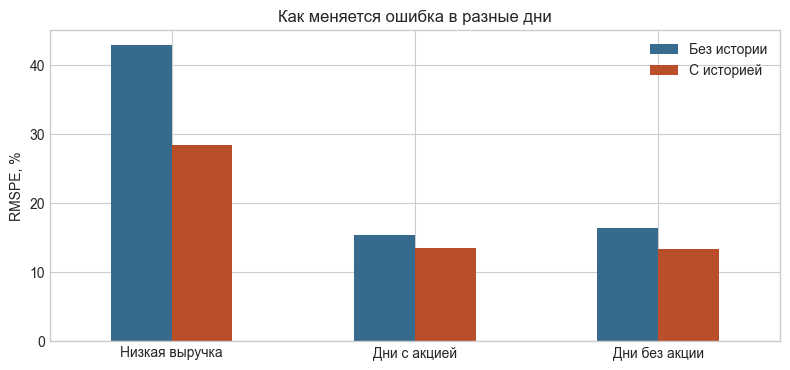

In [8]:
low = scored["Sales"] <= scored["Sales"].quantile(0.10)
groups = {
    "Низкая выручка": scored.loc[low],
    "Дни с акцией": scored.loc[~low & scored["Promo"].eq(1)],
    "Дни без акции": scored.loc[~low & scored["Promo"].eq(0)],
}

slices = []
examples = []
for label, rows in groups.items():
    errors = rows[list(names)].sub(rows["Sales"], axis=0).div(rows["Sales"], axis=0)
    rmspe = errors.pow(2).mean().pow(0.5).mul(100)
    slices.append({"Группа дней": label, "Дни с выручкой": len(rows), **rmspe.rename(names).to_dict()})
    relative = errors["with_history"].abs()
    example = rows.loc[(relative - relative.quantile(0.9)).abs().idxmin()]
    examples.append({
        "Группа дней": label,
        "Магазин": example["Store"],
        "Дата": example["Date"].date(),
        "Факт": example["Sales"],
        "Прогноз": round(example["with_history"]),
        "Ошибка, %": round(100 * (example["with_history"] / example["Sales"] - 1), 1),
    })

by_slice = pd.DataFrame(slices).set_index("Группа дней")
signed_error = scored["with_history"] / scored["Sales"] - 1
overprediction = signed_error.loc[low].gt(0).mean()
error_share = signed_error.loc[low].pow(2).sum() / signed_error.pow(2).sum()
print(f"Как часто завышаем прогноз в дни с низкой выручкой: {overprediction:.1%}")
print(f"Доля таких дней в сумме квадратов относительных ошибок: {error_share:.1%}")
display(by_slice.round(2))
display(pd.DataFrame(examples))
ax = by_slice[list(names.values())].plot(
    kind="bar", rot=0, figsize=(8, 3.8), color=["#376b8d", "#ba4e28"]
)
ax.set(title="Как меняется ошибка в разные дни", xlabel="", ylabel="RMSPE, %")
plt.tight_layout()
plt.show()

Из каждой группы взяли по одному примеру, где ошибка модели с историей была больше, чем примерно в 90% случаев в этой группе.

На графике ниже фактическая выручка магазина 1 и прогнозы двух моделей. Линии опускаются до нуля в дни, когда магазин не работал.

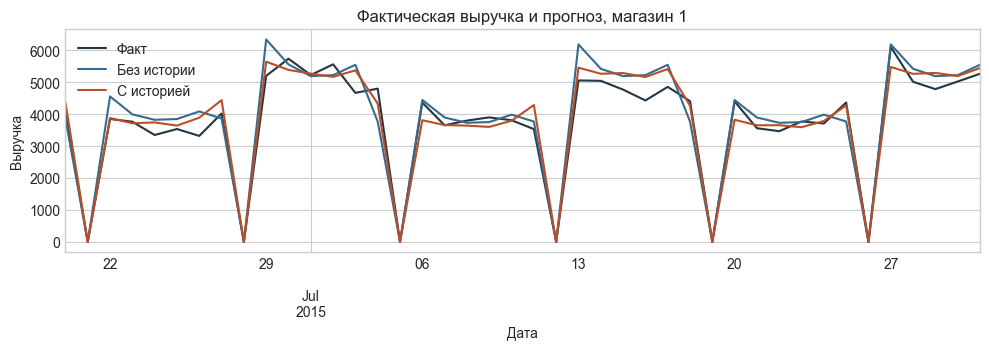

In [9]:
store_id = predictions["Store"].min()
store = predictions.loc[predictions["Store"] == store_id].sort_values("Date").set_index("Date")
lines = store[["Sales", "no_history", "with_history"]].rename(columns={"Sales": "Факт", **names})
ax = lines.plot(figsize=(10, 3.6), color=["#243543", "#376b8d", "#ba4e28"])
ax.set(title=f"Фактическая выручка и прогноз, магазин {store_id}", xlabel="Дата", ylabel="Выручка")
plt.tight_layout()
plt.show()

## Вывод

История продаж снизила RMSPE больше чем на 5% на всех трех периодах. Из отдельно проверенных признаков сильнее всего помогла выручка год назад. Самые большие ошибки относительно фактической выручки остались в дни с низкими продажами.

Дальше можно проверить, станет ли прогноз точнее, если отдельно сообщить модели, что выручка год назад неизвестна и вместо нее подставили медиану.